# PromptPiper — Visualizations

Organized by research question (see §Objectives in the paper):

1. **RQ1** — Trade-off between prompt compression and task performance
2. **RQ2** — How PromptPiper compares to existing baselines
3. **RQ3** — Cost and convergence characteristics
4. **RQ4** — Patterns in compression strategies and transferability

Missing results are skipped gracefully — re-run when new experiments complete.

In [1]:
import json
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

RESULTS_DIR = Path('../results/icse_26')

# Models — display name, directory name, access type
MODELS = [
    ('GPT-5.4-nano',         'gpt-5.4-nano-2026-03-17',    'remote'),
    ('Gemini-3-Flash',       'gemini-3-flash-preview',      'remote'),
    ('Gemma-4-26B',          'gemma-4-26b-a4b-it',          'local'),
    ('Qwen3.6-35B',          'qwen3.6-35b-a3b',             'local'),
]

# All tasks — (run_name_stem, display_label, local_only)
TASKS = [
    ('mbpp_instruct_nsga2',         'MBPP',        False),
    ('mmlu_pro_cs_nsga2',           'MMLU-Pro CS', False),
    ('gsm8k_cot_nsga2',             'GSM8K',       False),
    ('bbh_logical_deduction_nsga2', 'BBH-Logic',   False),
    ('musr_murder_mysteries_nsga2', 'MuSR',        True),
]
COMMON_TASKS  = [(s, l, lo) for s, l, lo in TASKS if not lo]
LOCAL_TASKS   = [(s, l, lo) for s, l, lo in TASKS if lo]

TRANSFER_PAIRS = [
    ('gsm8k_cot_nsga2',             'bbh_logical_deduction_nsga2'),
    ('bbh_logical_deduction_nsga2', 'gsm8k_cot_nsga2'),
]

BASELINE_STYLE = {
    'no_compression':      {'color': '#555555', 'marker': 'D', 'label': 'No compression'},
    'all_transformations': {'color': '#e06c75', 'marker': 's', 'label': 'All transforms'},
    'random_search':       {'color': '#d19a66', 'marker': '^', 'label': 'Random search'},
    'multi_armed_bandit':  {'color': '#e5c07b', 'marker': '*', 'label': 'MAB'},
    'summarization':       {'color': '#c678dd', 'marker': 'P', 'label': 'Summarization'},
    'truncated_prompt':    {'color': '#61afef', 'marker': 'v', 'label': 'Truncated'},
    'random_deletion':     {'color': '#56b6c2', 'marker': 'X', 'label': 'Rand. deletion'},
    'llmlingua2':          {'color': '#98c379', 'marker': 'h', 'label': 'LLMLingua-2'},
}

NSGA2_COLOR   = '#2196F3'
SEARCH_COLOR  = '#90CAF9'

MODEL_COLORS = ['#e41a1c','#377eb8','#4daf4a','#984ea3']

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

# ── Loaders ───────────────────────────────────────────────────────────────────

def load_json(path):
    try:
        with open(path) as f:
            return json.load(f)
    except Exception:
        return None

def load_jsonl(path):
    try:
        with open(path) as f:
            return [json.loads(l) for l in f]
    except Exception:
        return None

def all_results():
    """Return nested dict: results[model_dir][run_stem] = data."""
    out = {}
    for _, mdir, _ in MODELS:
        out[mdir] = {}
        mpath = RESULTS_DIR / mdir
        if not mpath.exists():
            continue
        for stem, _, _ in TASKS:
            d = load_json(mpath / f'{stem}.json')
            if d:
                out[mdir][stem] = d
        for src, tgt in TRANSFER_PAIRS:
            d = load_json(mpath / f'transfer_{src}_to_{tgt}.json')
            if d:
                out[mdir][f'transfer_{src}_to_{tgt}'] = d
    return out

def all_detailed():
    """Return nested dict: detailed[model_dir][run_stem] = list of row dicts."""
    out = {}
    for _, mdir, _ in MODELS:
        out[mdir] = {}
        det_path = RESULTS_DIR / mdir / 'detailed'
        if not det_path.exists():
            continue
        for stem, _, _ in TASKS:
            rows = load_jsonl(det_path / f'{stem}_detailed.jsonl')
            if rows:
                out[mdir][stem] = rows
        for src, tgt in TRANSFER_PAIRS:
            key = f'transfer_{src}_to_{tgt}'
            rows = load_jsonl(det_path / f'{key}_detailed.jsonl')
            if rows:
                out[mdir][key] = rows
    return out

RESULTS  = all_results()
DETAILED = all_detailed()

print('Results loaded:')
for mlabel, mdir, _ in MODELS:
    runs = list(RESULTS[mdir].keys())
    det  = list(DETAILED[mdir].keys())
    print(f'  {mlabel}: {len(runs)} runs, {len(det)} detailed')


Results loaded:
  GPT-5.4-nano: 6 runs, 6 detailed
  Gemini-3-Flash: 6 runs, 6 detailed
  Gemma-4-26B: 7 runs, 0 detailed
  Qwen3.6-35B: 1 runs, 0 detailed


---
## RQ1 — Trade-off between Prompt Compression and Task Performance

> *What is the trade-off between prompt compression and task performance?*

Each subplot shows the NSGA-II Pareto front (search set in light blue, test set in dark blue) and all baselines evaluated on the test set.

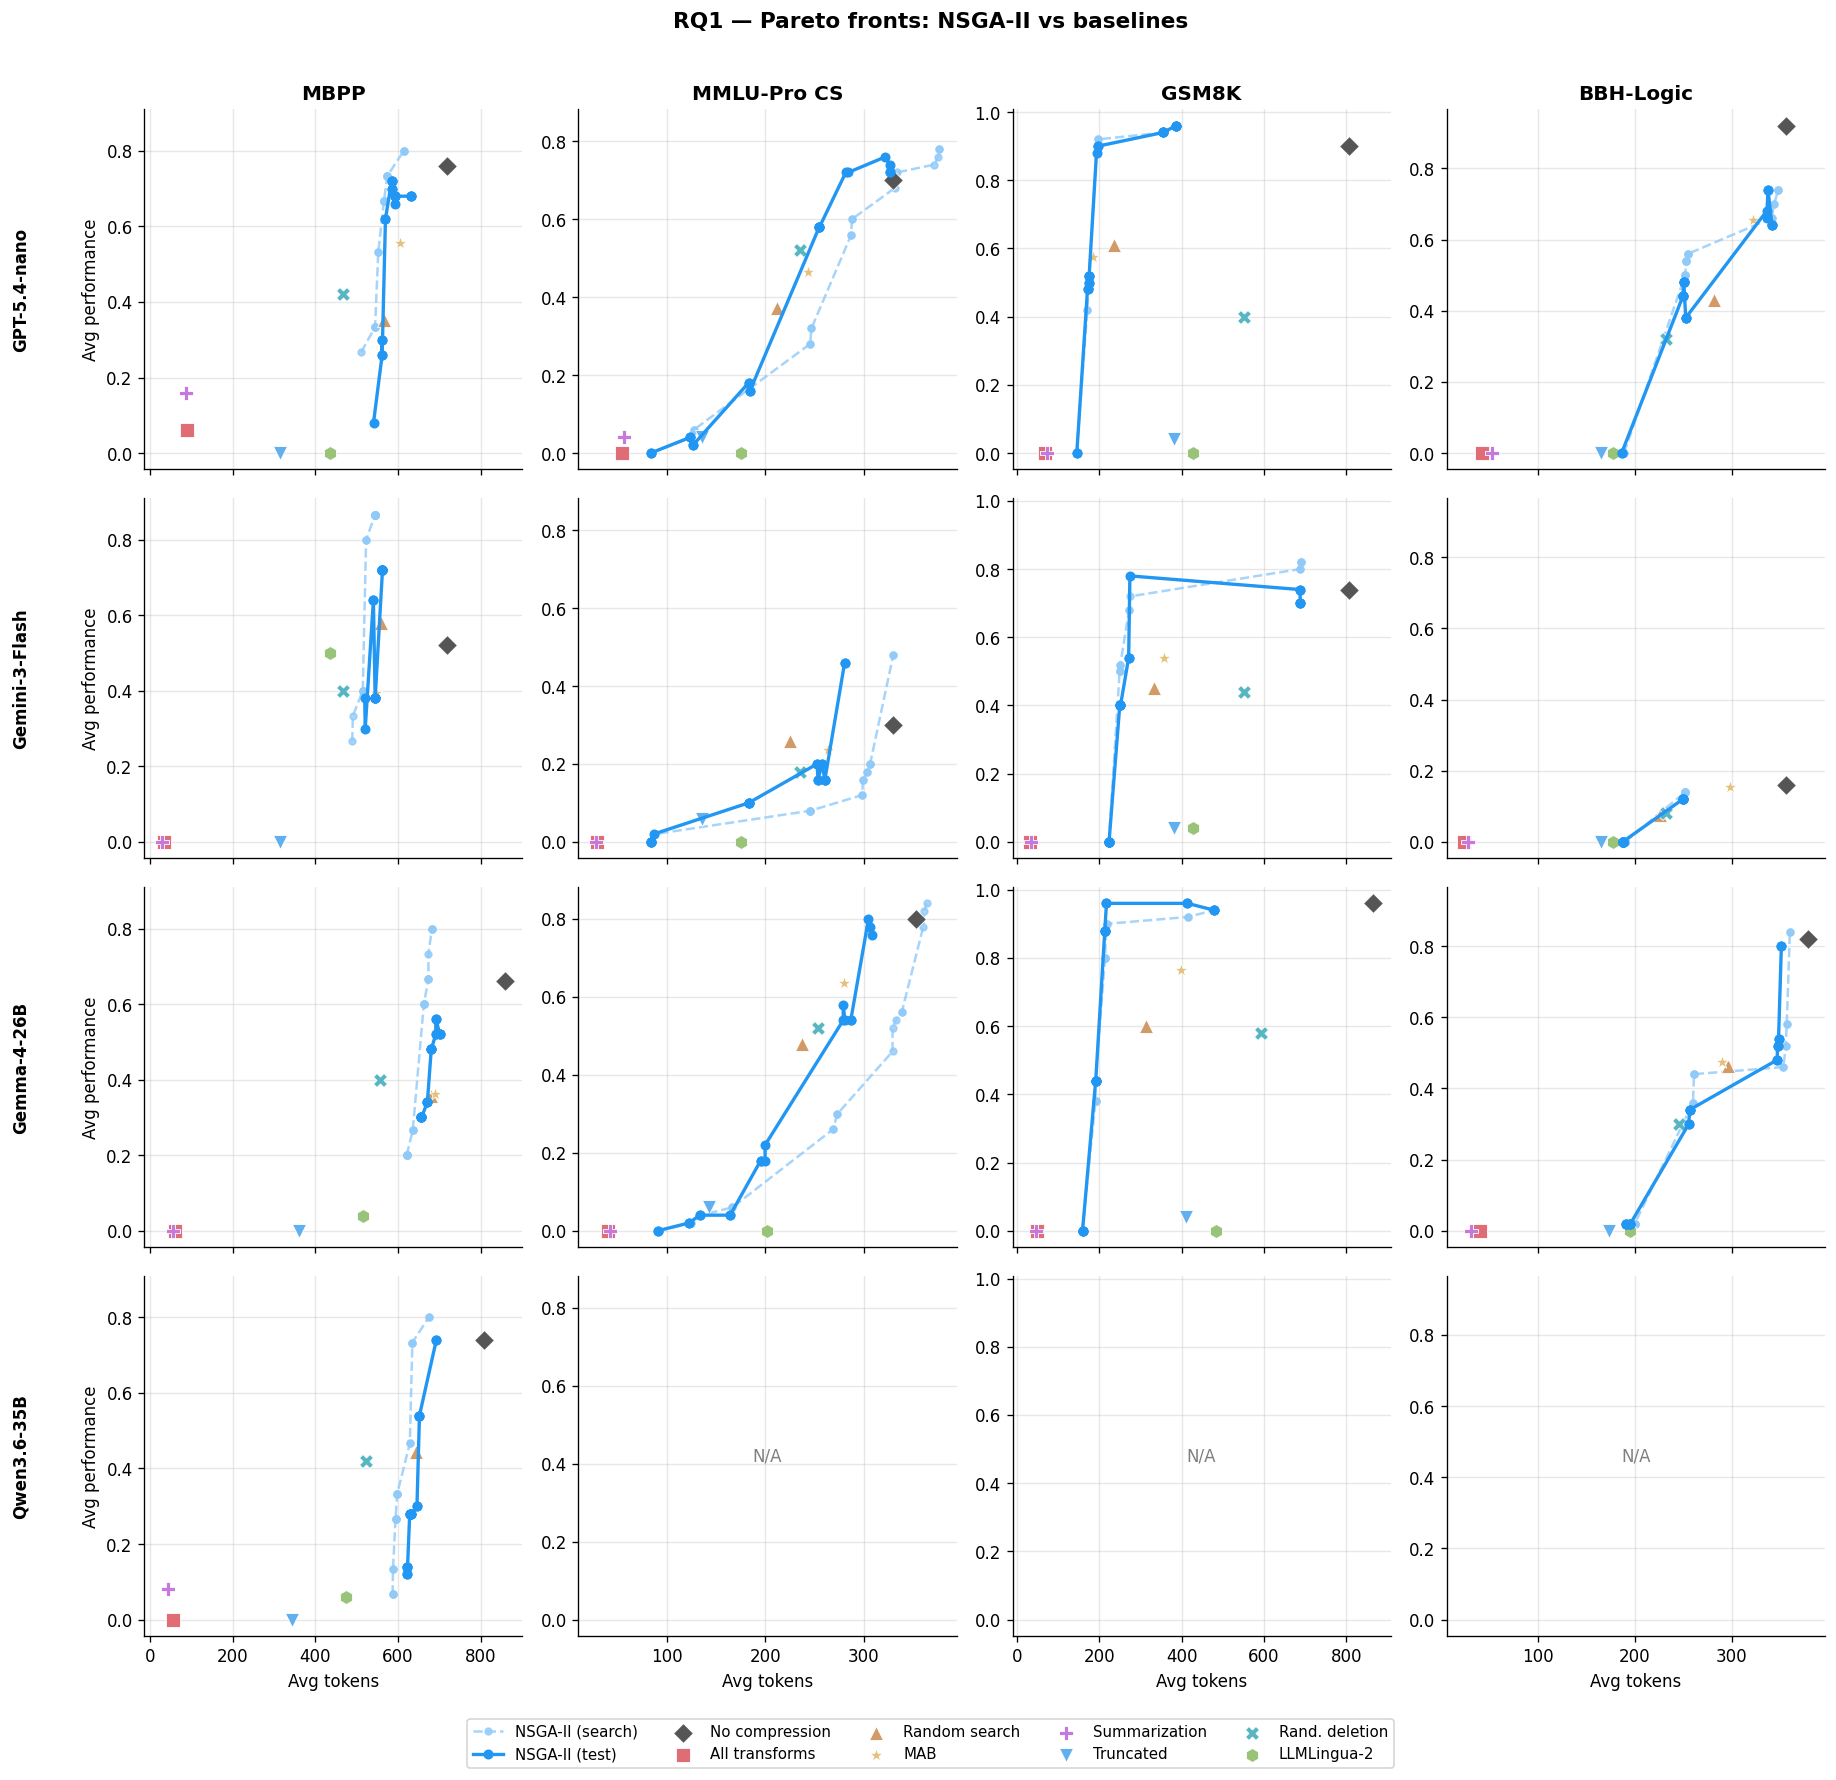

In [2]:
# Helper: extract (tokens, perf) for a list of solutions from JSON
def pareto_xy_json(solutions, split='test'):
    tok  = [s.get(f'{split}_avg_tokens')      or s['search_avg_tokens']      for s in solutions]
    perf = [s.get(f'{split}_avg_performance') or s['search_avg_performance'] for s in solutions]
    return np.array(tok), np.array(perf)

def draw_pareto_front(ax, tokens, perfs, color, label, lw=2, ms=5, ls='-'):
    order = np.argsort(tokens)
    ax.plot(tokens[order], perfs[order], f'o{ls}', color=color, lw=lw,
            markersize=ms, label=label, zorder=6)

def draw_baselines(ax, baselines, split='test'):
    for bl in baselines:
        bname = bl['name']
        if bname not in BASELINE_STYLE:
            continue
        st = BASELINE_STYLE[bname]
        bt = bl.get(f'{split}_avg_tokens')      or bl['search_avg_tokens']
        bp = bl.get(f'{split}_avg_performance') or bl['search_avg_performance']
        ax.scatter(bt, bp, s=80, label=st['label'],
                   color=st['color'], marker=st['marker'],
                   zorder=5, edgecolors='white', linewidths=0.5)


def rq1_grid(task_list, title_suffix=''):
    available_models = [(lbl, mdir) for lbl, mdir, _ in MODELS
                        if any(stem in RESULTS[mdir] for stem, _, _ in task_list)]
    available_tasks  = [(stem, lbl) for stem, lbl, _ in task_list
                        if any(stem in RESULTS[mdir] for _, mdir, _ in MODELS)]
    if not available_models or not available_tasks:
        print('No data available.')
        return

    nrows, ncols = len(available_models), len(available_tasks)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(3.8 * ncols, 3.5 * nrows),
                             squeeze=False,
                             sharey='col', sharex='col')

    legend_handles = {}

    for ri, (mlabel, mdir) in enumerate(available_models):
        for ci, (stem, tlabel) in enumerate(available_tasks):
            ax = axes[ri][ci]
            ax.set_xlabel('Avg tokens' if ri == nrows - 1 else '')
            ax.set_ylabel('Avg performance' if ci == 0 else '')
            if ri == 0:
                ax.set_title(tlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(mlabel, xy=(-0.35, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')

            d = RESULTS[mdir].get(stem)
            if d is None:
                ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes,
                        ha='center', va='center', color='gray')
                ax.set_visible(True)
                continue

            # Search pareto front
            stok, sperf = pareto_xy_json(d['pareto_solutions'], split='search')
            h, = ax.plot(*[x[np.argsort(stok)] for x in (stok, sperf)],
                         'o--', color=SEARCH_COLOR, lw=1.5, markersize=4,
                         label='NSGA-II (search)', zorder=5, alpha=0.8)
            legend_handles.setdefault('NSGA-II (search)', h)

            # Test pareto front
            ttok, tperf = pareto_xy_json(d['pareto_solutions'], split='test')
            h, = ax.plot(*[x[np.argsort(ttok)] for x in (ttok, tperf)],
                         'o-', color=NSGA2_COLOR, lw=2, markersize=5,
                         label='NSGA-II (test)', zorder=6)
            legend_handles.setdefault('NSGA-II (test)', h)

            # Baselines on test
            for bl in d['baselines']:
                bname = bl['name']
                if bname not in BASELINE_STYLE:
                    continue
                st = BASELINE_STYLE[bname]
                bt = bl.get('test_avg_tokens')       or bl['search_avg_tokens']
                bp = bl.get('test_avg_performance')  or bl['search_avg_performance']
                h = ax.scatter(bt, bp, s=70, color=st['color'], marker=st['marker'],
                               zorder=5, edgecolors='white', linewidths=0.5,
                               label=st['label'])
                legend_handles.setdefault(st['label'], h)

    handles = list(legend_handles.values())
    labels  = list(legend_handles.keys())
    fig.legend(handles, labels, loc='lower center',
               ncol=min(5, len(labels)),
               bbox_to_anchor=(0.5, -0.04), frameon=True, fontsize=9)
    fig.suptitle(f'RQ1 — Pareto fronts: NSGA-II vs baselines{title_suffix}',
                 fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


rq1_grid(COMMON_TASKS)


### RQ1 — Variant: Pareto fronts from `detailed/` results (per-example aggregation)

For models with detailed results, each solution's test performance and token count
are computed by averaging over individual examples in the held-out test set.

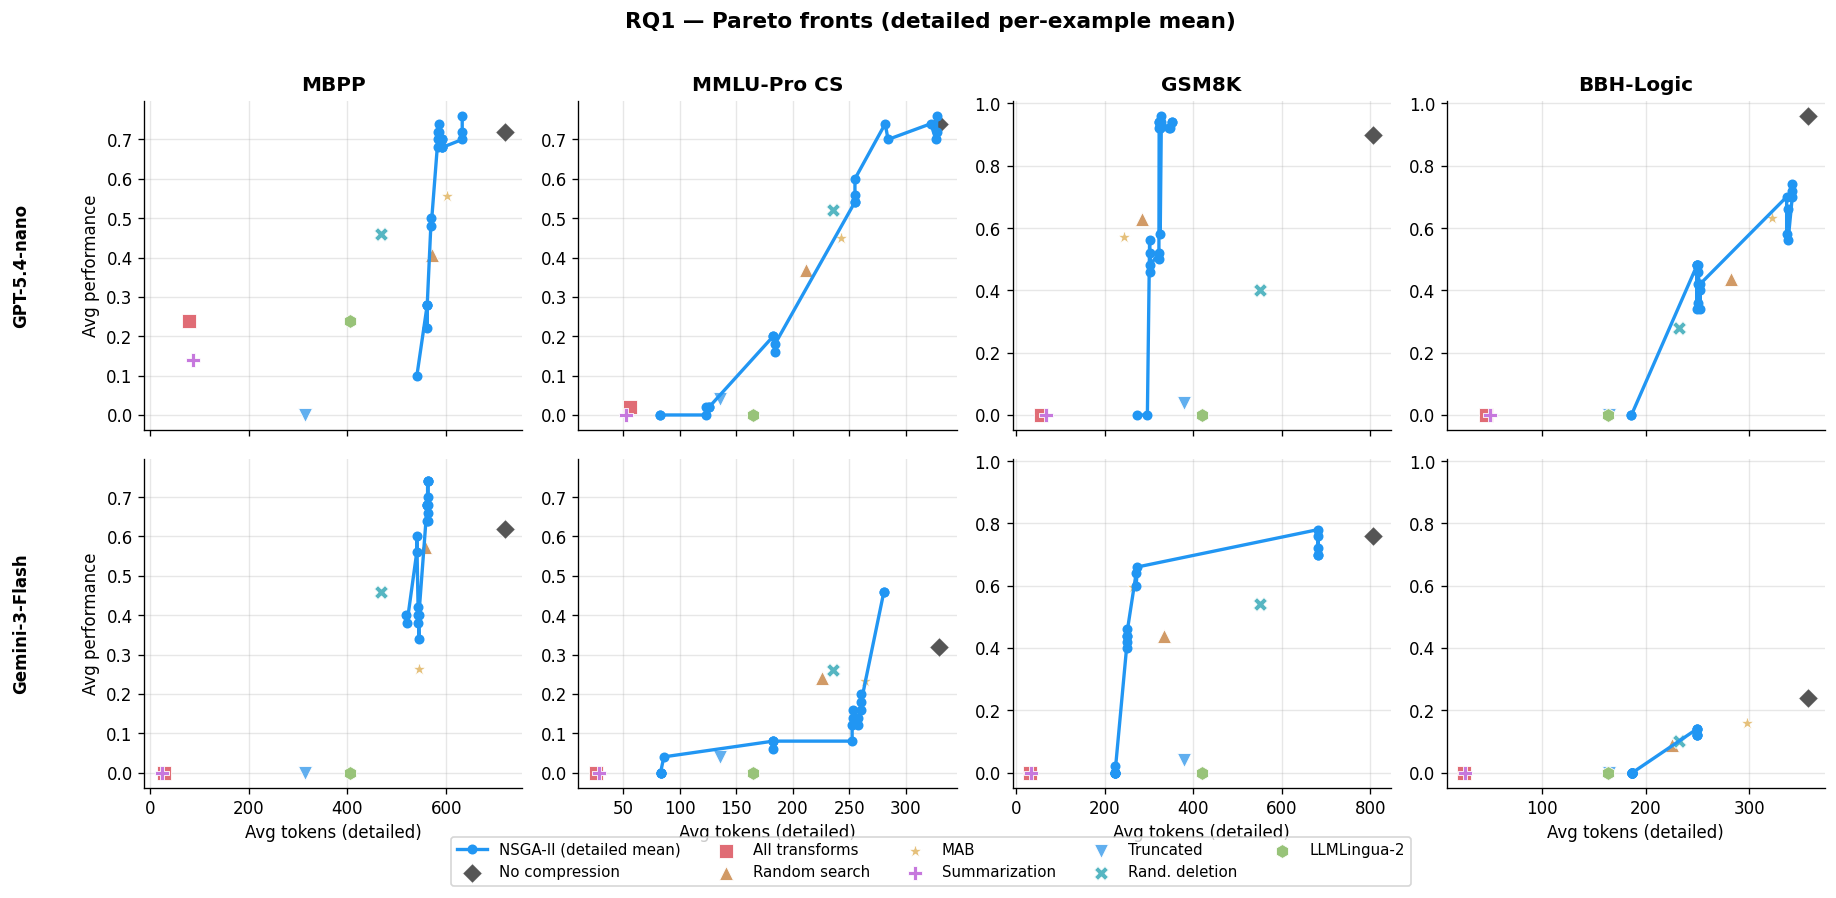

In [4]:
def aggregate_detailed_solutions(rows, solution_type='pareto'):
    """Aggregate detailed JSONL rows into per-solution mean (tokens, perf)."""
    filtered = [r for r in rows if r['solution_type'] == solution_type]
    by_sol = defaultdict(list)
    for r in filtered:
        by_sol[r['solution_id']].append(r)
    solutions = []
    for sol_id, sol_rows in sorted(by_sol.items()):
        solutions.append({
            'solution_id': sol_id,
            'avg_tokens': np.mean([r['compressed_tokens'] for r in sol_rows]),
            'avg_performance': np.mean([r['performance'] for r in sol_rows]),
            'transformation_names': sol_rows[0].get('transformation_names', []),
            'transformation_ids':   sol_rows[0].get('transformation_ids', []),
        })
    return solutions


def rq1_grid_detailed(task_list, title_suffix=''):
    has_detailed = [(lbl, mdir) for lbl, mdir, _ in MODELS
                    if any(stem in DETAILED[mdir] for stem, _, _ in task_list)]
    available_tasks = [(stem, lbl) for stem, lbl, _ in task_list
                       if any(stem in DETAILED[mdir] for _, mdir, _ in MODELS)]
    if not has_detailed or not available_tasks:
        print('No detailed results available.')
        return

    nrows, ncols = len(has_detailed), len(available_tasks)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(3.8 * ncols, 3.5 * nrows),
                             squeeze=False,
                             sharey='col', sharex='col')

    legend_handles = {}

    for ri, (mlabel, mdir) in enumerate(has_detailed):
        for ci, (stem, tlabel) in enumerate(available_tasks):
            ax = axes[ri][ci]
            ax.set_xlabel('Avg tokens (detailed)' if ri == nrows - 1 else '')
            ax.set_ylabel('Avg performance' if ci == 0 else '')
            if ri == 0:
                ax.set_title(tlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(mlabel, xy=(-0.35, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')

            rows = DETAILED[mdir].get(stem)
            d    = RESULTS[mdir].get(stem)
            if rows is None:
                ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes,
                        ha='center', va='center', color='gray')
                continue

            # Pareto solutions from detailed
            pareto_sols = aggregate_detailed_solutions(rows, 'pareto')
            toks  = np.array([s['avg_tokens']      for s in pareto_sols])
            perfs = np.array([s['avg_performance'] for s in pareto_sols])
            order = np.argsort(toks)
            h, = ax.plot(toks[order], perfs[order], 'o-', color=NSGA2_COLOR,
                         lw=2, markersize=5, label='NSGA-II (detailed mean)', zorder=6)
            legend_handles.setdefault('NSGA-II (detailed mean)', h)

            # Baselines aggregated from detailed
            for bname in BASELINE_STYLE:
                sol_type = f'baseline_{bname}'
                bl_sols = aggregate_detailed_solutions(rows, sol_type)
                if not bl_sols:
                    continue
                st = BASELINE_STYLE[bname]
                bt = np.mean([s['avg_tokens']      for s in bl_sols])
                bp = np.mean([s['avg_performance'] for s in bl_sols])
                h = ax.scatter(bt, bp, s=70, color=st['color'], marker=st['marker'],
                               zorder=5, edgecolors='white', linewidths=0.5,
                               label=st['label'])
                legend_handles.setdefault(st['label'], h)

    handles = list(legend_handles.values())
    labels  = list(legend_handles.keys())
    fig.legend(handles, labels, loc='lower center',
               ncol=min(5, len(labels)),
               bbox_to_anchor=(0.5, -0.04), frameon=True, fontsize=9)
    fig.suptitle(f'RQ1 — Pareto fronts (detailed per-example mean){title_suffix}',
                 fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


rq1_grid_detailed(COMMON_TASKS)


### RQ1 — Local-model benchmark (MuSR)

MuSR is run only on self-hosted models. This plot shows the Pareto fronts for all local models that have results.

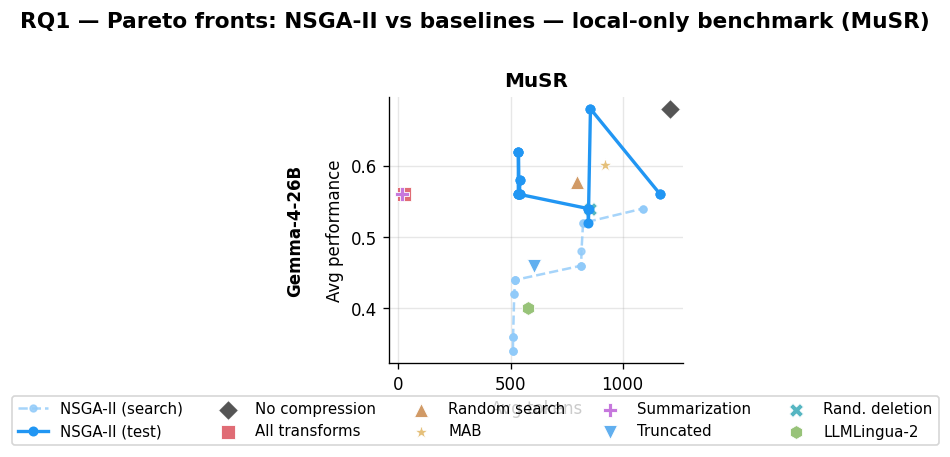

In [5]:
rq1_grid(LOCAL_TASKS, title_suffix=' — local-only benchmark (MuSR)')


---
## RQ2 — How PromptPiper Compares to Existing Baselines

> *How does PromptPiper compare to existing baselines for prompt optimization?*

Distributions of per-example **performance** (left column) and **compressed tokens** (right column)
from the detailed results. Rows correspond to benchmarks. Each method's distribution is shown as a violin.

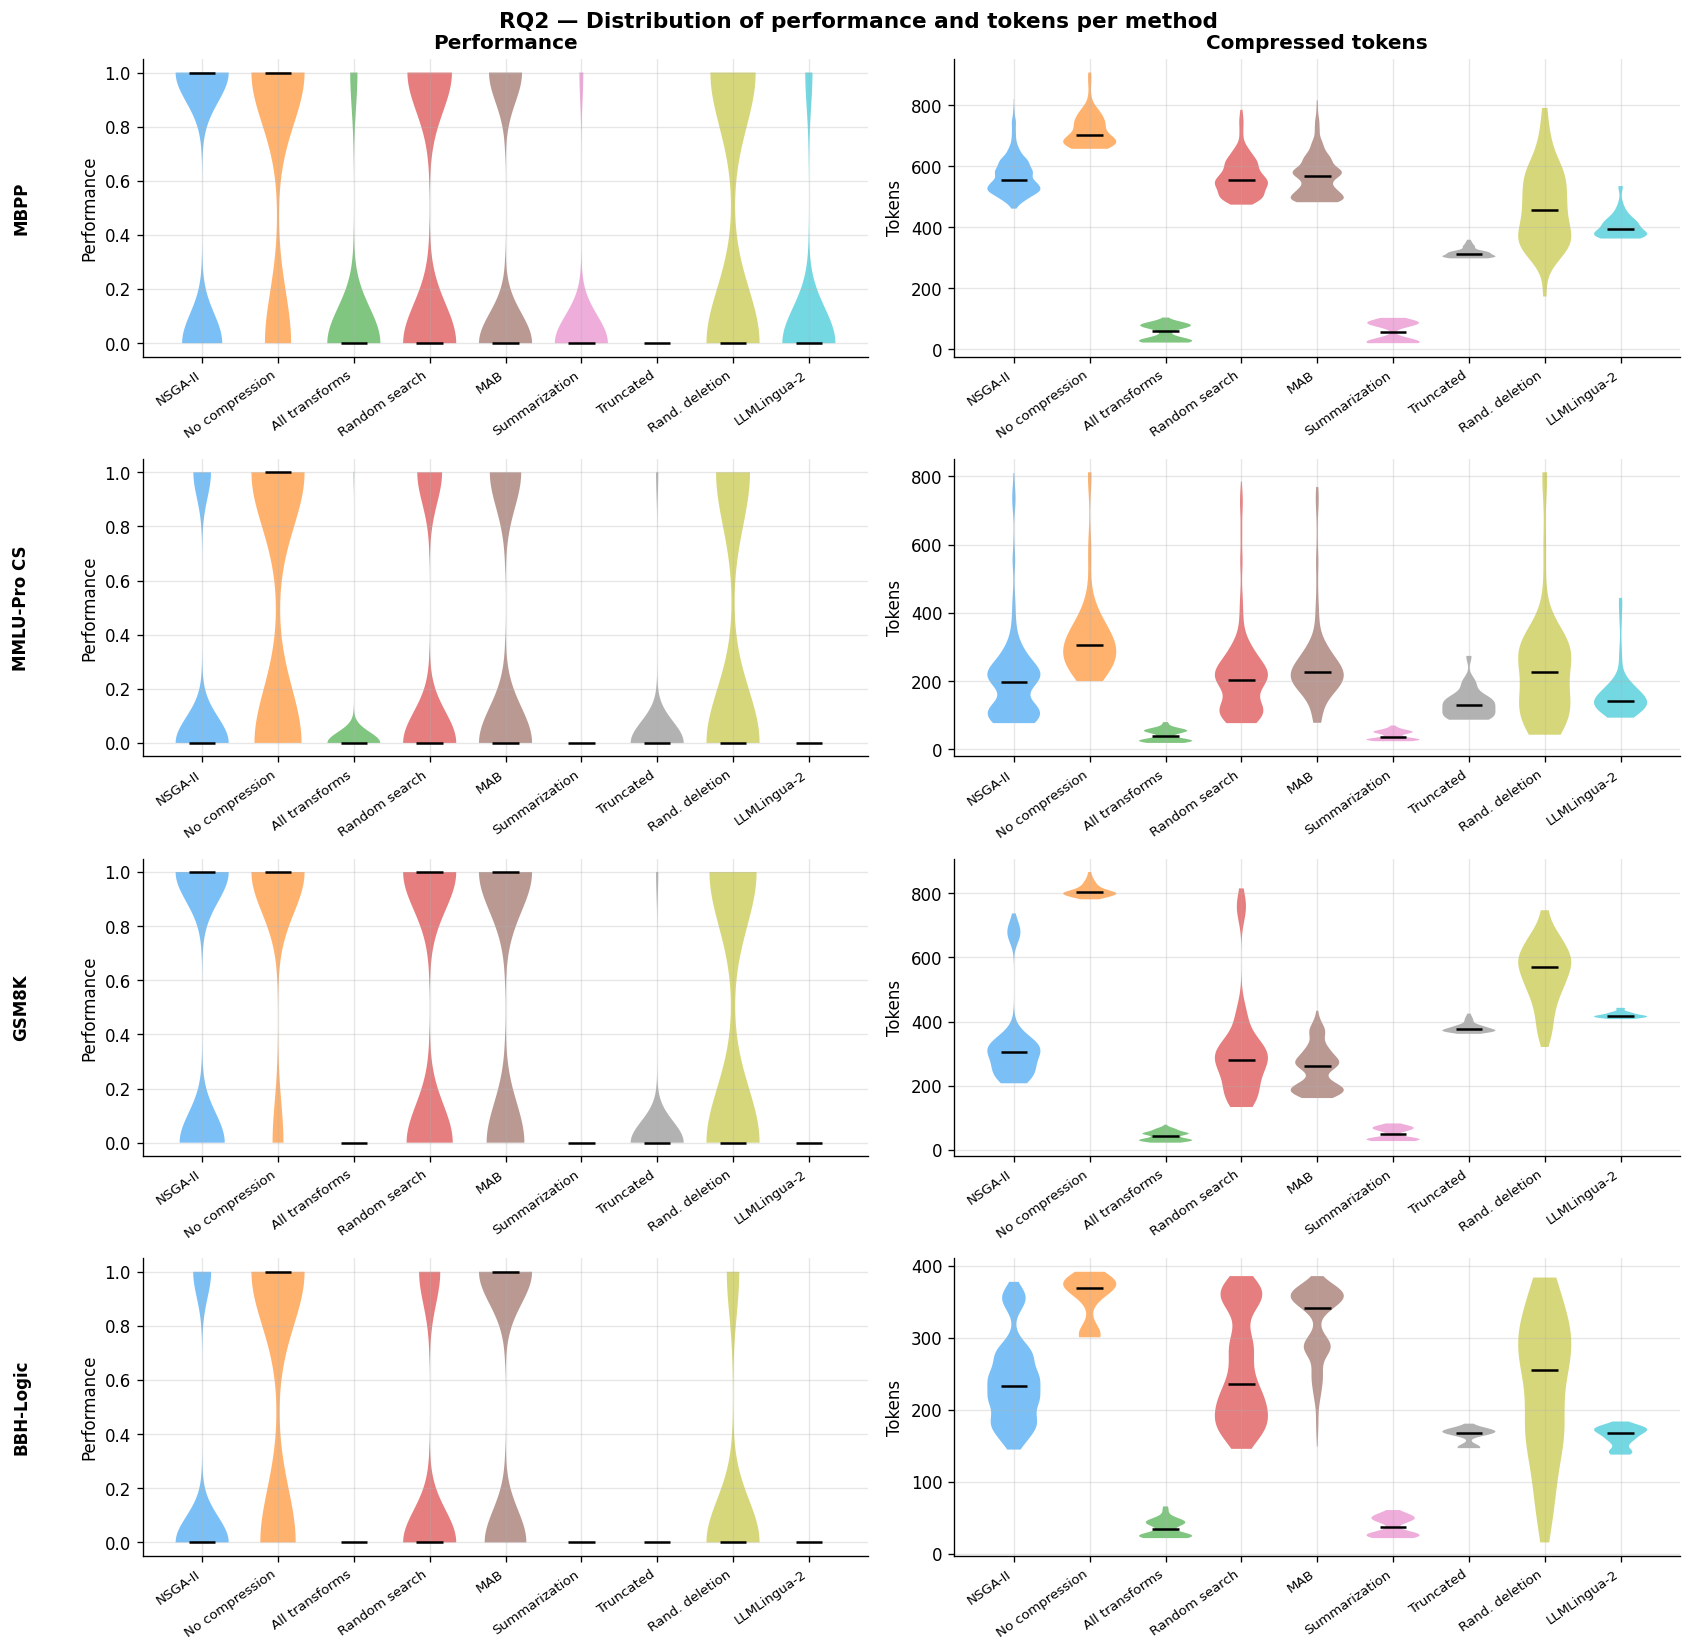

In [6]:
def collect_rq2_data():
    """Collect per-example perf & tokens from detailed results for all models × tasks."""
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            det = DETAILED[mdir].get(stem)
            if det is None:
                continue
            for row in det:
                sol_type = row['solution_type']
                if sol_type == 'pareto':
                    method = 'NSGA-II'
                elif sol_type.startswith('baseline_'):
                    bname = sol_type.replace('baseline_', '')
                    method = BASELINE_STYLE.get(bname, {}).get('label', bname)
                else:
                    continue
                rows.append({
                    'model': mlabel,
                    'task':  tlabel,
                    'method': method,
                    'performance': row['performance'],
                    'compressed_tokens': row['compressed_tokens'],
                })
    return pd.DataFrame(rows)


df_rq2 = collect_rq2_data()

if df_rq2.empty:
    print('No detailed results available for RQ2 plots.')
else:
    tasks_with_data  = [l for _, l, _ in TASKS if l in df_rq2['task'].unique()]
    methods_ordered  = (['NSGA-II']
                        + [st['label'] for st in BASELINE_STYLE.values()
                           if st['label'] in df_rq2['method'].unique()])
    methods_ordered  = list(dict.fromkeys(methods_ordered))

    method_colors = {m: c for m, c in zip(
        methods_ordered,
        plt.cm.tab10(np.linspace(0, 1, len(methods_ordered))))}
    method_colors['NSGA-II'] = NSGA2_COLOR

    nrows = len(tasks_with_data)
    ncols = 2  # performance | tokens

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(14, 3.5 * nrows), squeeze=False)

    for ri, tlabel in enumerate(tasks_with_data):
        sub = df_rq2[df_rq2['task'] == tlabel]

        for ci, (metric, xlabel) in enumerate([
                ('performance', 'Performance'), ('compressed_tokens', 'Compressed tokens')]):
            ax = axes[ri][ci]

            positions = list(range(len(methods_ordered)))
            data_per_method = [sub[sub['method'] == m][metric].dropna().values
                               for m in methods_ordered]

            for pos, (m, data) in enumerate(zip(methods_ordered, data_per_method)):
                if len(data) == 0:
                    continue
                parts = ax.violinplot([data], positions=[pos], widths=0.7,
                                      showmedians=True, showextrema=False)
                color = method_colors[m]
                for pc in parts['bodies']:
                    pc.set_facecolor(color)
                    pc.set_alpha(0.6)
                parts['cmedians'].set_color('black')
                parts['cmedians'].set_linewidth(1.5)

            ax.set_xticks(positions)
            ax.set_xticklabels(methods_ordered, rotation=35, ha='right', fontsize=8)
            ax.set_ylabel(xlabel if ci == 0 else 'Tokens')
            if ri == 0:
                ax.set_title(xlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(tlabel, xy=(-0.18, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')

    fig.suptitle('RQ2 — Distribution of performance and tokens per method',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


---
## RQ3 — Cost and Convergence Characteristics

> *What are the cost and convergence characteristics of different optimization strategies?*

### RQ3.1 — Cumulative search + test time per approach

Box plots showing the distribution of total elapsed time (search + evaluation) across
available runs, broken down by model and benchmark.

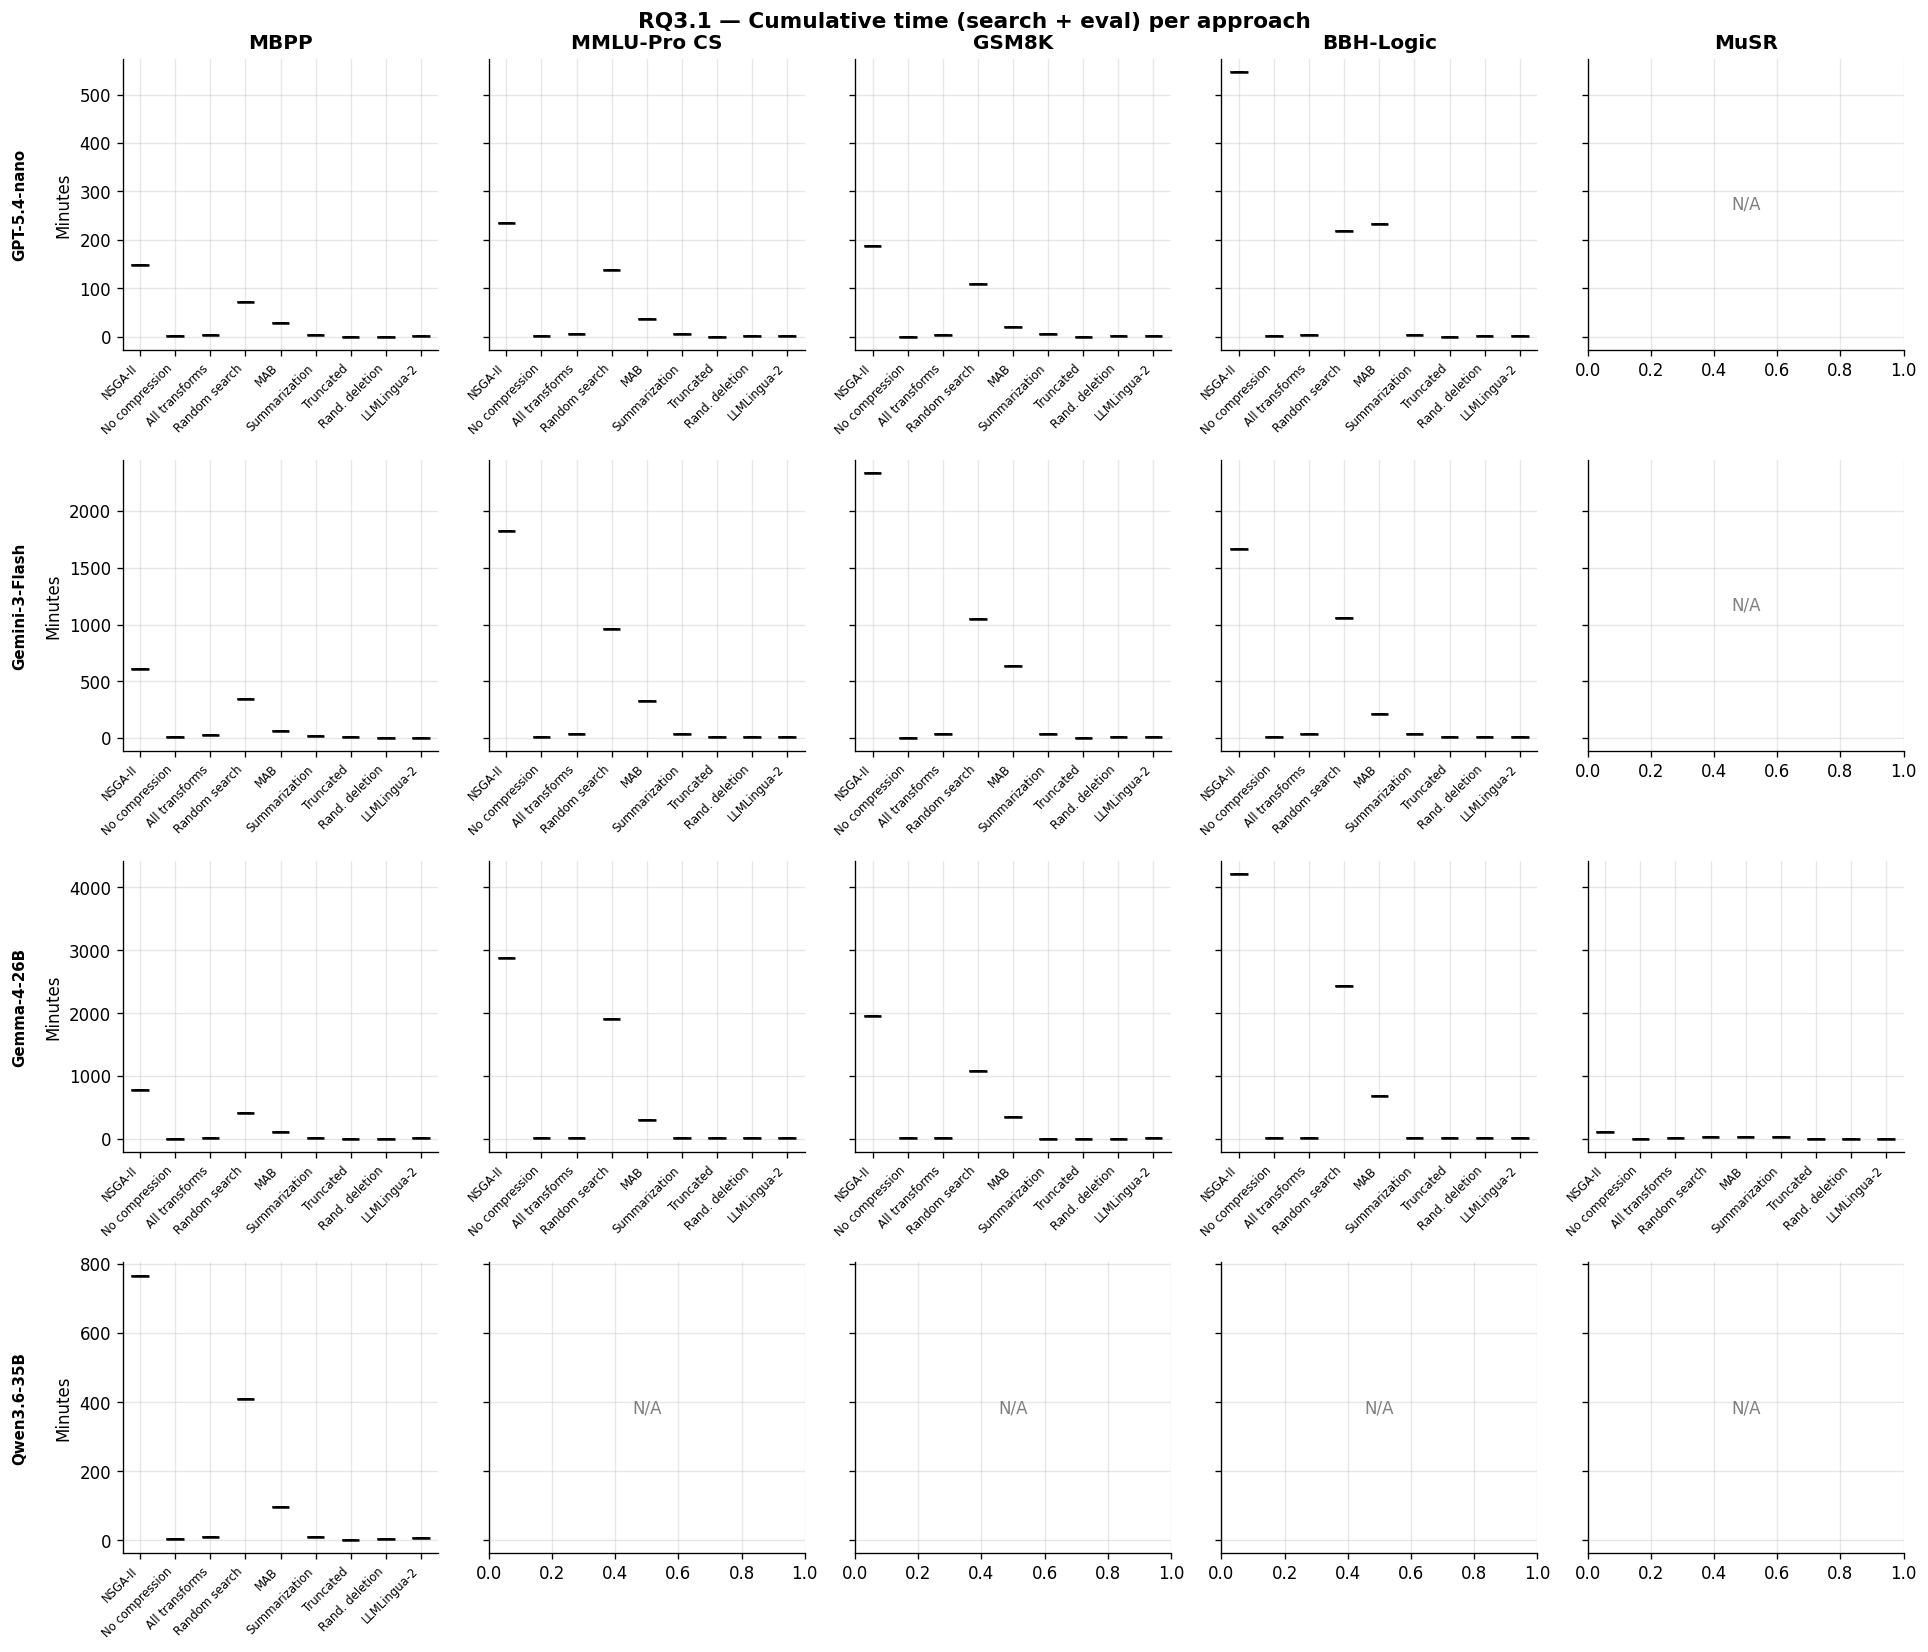

In [7]:
def collect_timing():
    rows = []
    approach_order = ['NSGA-II'] + [st['label'] for st in BASELINE_STYLE.values()]

    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            rows.append({
                'model': mlabel, 'task': tlabel,
                'approach': 'NSGA-II',
                'total_seconds': d['search_elapsed_seconds'] + d['eval_elapsed_seconds'],
            })
            for bl in d['baselines']:
                bname = bl['name']
                label = BASELINE_STYLE.get(bname, {}).get('label', bname)
                rows.append({
                    'model': mlabel, 'task': tlabel,
                    'approach': label,
                    'total_seconds': bl.get('elapsed_seconds', np.nan),
                })
    return pd.DataFrame(rows)


df_time = collect_timing()

if df_time.empty:
    print('No timing data available.')
else:
    df_time['total_minutes'] = df_time['total_seconds'] / 60

    approaches = (['NSGA-II']
                  + [st['label'] for st in BASELINE_STYLE.values()
                     if st['label'] in df_time['approach'].unique()])
    approaches = list(dict.fromkeys(approaches))

    models_present = [lbl for lbl, _, _ in MODELS if lbl in df_time['model'].unique()]
    tasks_present  = [lbl for _, lbl, _ in TASKS  if lbl in df_time['task'].unique()]

    nrows = len(models_present)
    ncols = len(tasks_present)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(3.2 * ncols, 3.5 * nrows),
                             squeeze=False, sharey='row')

    for ri, mlabel in enumerate(models_present):
        for ci, tlabel in enumerate(tasks_present):
            ax = axes[ri][ci]
            sub = df_time[(df_time['model'] == mlabel) & (df_time['task'] == tlabel)]

            if ri == 0:
                ax.set_title(tlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(mlabel, xy=(-0.35, 0.5), xycoords='axes fraction',
                            fontsize=9, fontweight='bold', rotation=90, va='center')
                ax.set_ylabel('Minutes')

            if sub.empty:
                ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes,
                        ha='center', va='center', color='gray')
                continue

            data = [sub[sub['approach'] == a]['total_minutes'].dropna().values
                    for a in approaches]
            bp = ax.boxplot([d if len(d) else [np.nan] for d in data],
                            labels=approaches, patch_artist=True,
                            medianprops=dict(color='black', lw=1.5))
            colors = ([NSGA2_COLOR]
                      + [BASELINE_STYLE[k]['color']
                         for k in BASELINE_STYLE
                         if BASELINE_STYLE[k]['label'] in approaches[1:]])
            for patch, color in zip(bp['boxes'], colors[:len(bp['boxes'])]):
                patch.set_facecolor(color)
                patch.set_alpha(0.7)
            ax.set_xticklabels(approaches, rotation=45, ha='right', fontsize=7)

    fig.suptitle('RQ3.1 — Cumulative time (search + eval) per approach',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


### RQ3.2 — Time distribution across models (per task)

Box plots showing how each approach's total time varies across models, aggregated per task.

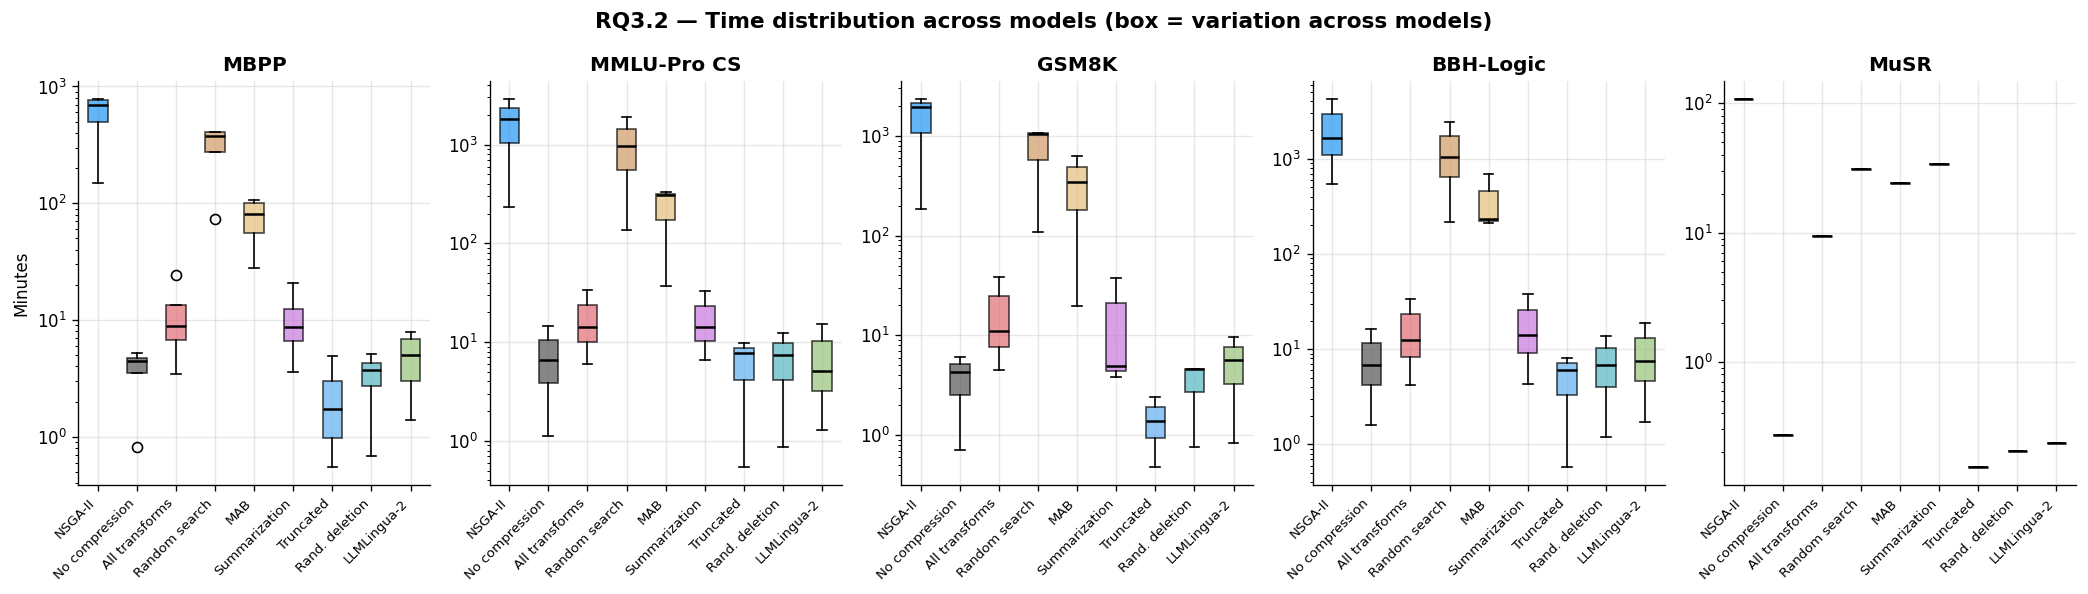

In [13]:
if df_time.empty:
    print('No timing data available.')
else:
    tasks_present  = [lbl for _, lbl, _ in TASKS if lbl in df_time['task'].unique()]
    approaches_avail = list(dict.fromkeys(
        ['NSGA-II'] + [st['label'] for st in BASELINE_STYLE.values()
                        if st['label'] in df_time['approach'].unique()]))

    ncols = len(tasks_present)
    fig, axes = plt.subplots(1, ncols, figsize=(3.5 * ncols, 5), squeeze=False, sharey=False)

    for ci, tlabel in enumerate(tasks_present):
        ax = axes[0][ci]
        sub = df_time[df_time['task'] == tlabel]
        data = [sub[sub['approach'] == a]['total_minutes'].dropna().values
                for a in approaches_avail]
        bp = ax.boxplot([d if len(d) else [np.nan] for d in data],
                        labels=approaches_avail, patch_artist=True,
                        medianprops=dict(color='black', lw=1.5))
        colors_bl = ([NSGA2_COLOR]
                     + [BASELINE_STYLE[k]['color']
                        for k in BASELINE_STYLE
                        if BASELINE_STYLE[k]['label'] in approaches_avail[1:]])
        for patch, color in zip(bp['boxes'], colors_bl[:len(bp['boxes'])]):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        ax.set_title(tlabel, fontweight='bold')
        ax.set_xticklabels(approaches_avail, rotation=45, ha='right', fontsize=8)
        ax.set_ylabel('Minutes' if ci == 0 else '')
        ax.set_yscale('log')

    fig.suptitle('RQ3.2 — Time distribution across models (box = variation across models)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


### RQ3.3 — Convergence: aggregated per task, averaged across models

Lines show the mean best performance and mean minimum tokens across models. Shaded regions show ±1 standard deviation.

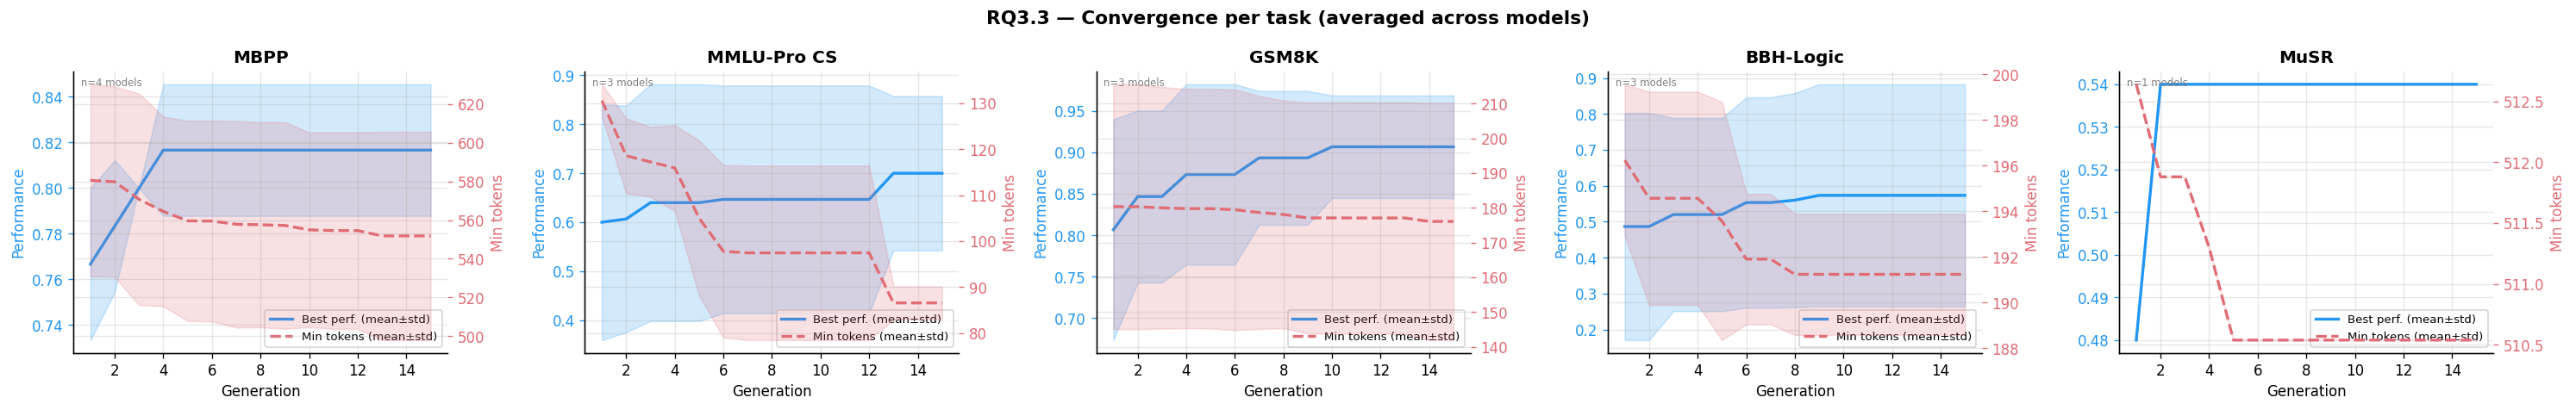

In [14]:
def collect_convergence():
    """Return dict task_label -> list of generation histories (one per model)."""
    out = defaultdict(list)
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            history = d.get('generation_history', [])
            if not history:
                continue
            out[tlabel].append({'model': mlabel, 'history': history})
    return out


conv_data = collect_convergence()

if not conv_data:
    print('No generation history data available.')
else:
    tasks_conv = list(conv_data.keys())
    ncols = min(5, len(tasks_conv))
    nrows = (len(tasks_conv) + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(5 * ncols, 4 * nrows), squeeze=False)

    for idx, tlabel in enumerate(tasks_conv):
        ax = axes[idx // ncols][idx % ncols]
        entries = conv_data[tlabel]

        # Collect best_perf and min_tokens per generation per model
        n_gens = max(h['history'][-1]['generation'] for h in entries)
        gens = list(range(1, n_gens + 1))

        all_best_perf = []
        all_min_tok   = []

        for entry in entries:
            gen_map = {h['generation']: h for h in entry['history']}
            bp_series = []
            mt_series = []
            for g in gens:
                h = gen_map.get(g)
                if h and h['pareto_front']:
                    bp_series.append(max(s['avg_performance'] for s in h['pareto_front']))
                    mt_series.append(min(s['avg_tokens']      for s in h['pareto_front']))
                else:
                    bp_series.append(np.nan)
                    mt_series.append(np.nan)
            all_best_perf.append(bp_series)
            all_min_tok.append(mt_series)

        def plot_mean_std(ax, gens, data, color, label, ls='-'):
            arr = np.array(data, dtype=float)
            mean = np.nanmean(arr, axis=0)
            std  = np.nanstd(arr, axis=0)
            ax.plot(gens, mean, color=color, lw=2, ls=ls, label=label)
            ax.fill_between(gens, mean - std, mean + std, color=color, alpha=0.2)

        ax2 = ax.twinx()
        plot_mean_std(ax,  gens, all_best_perf, '#2196F3', 'Best perf. (mean±std)')
        plot_mean_std(ax2, gens, all_min_tok,   '#e06c75', 'Min tokens (mean±std)', ls='--')

        ax.set_xlabel('Generation')
        ax.set_ylabel('Performance', color='#2196F3')
        ax.tick_params(axis='y', colors='#2196F3')
        ax2.set_ylabel('Min tokens', color='#e06c75')
        ax2.tick_params(axis='y', colors='#e06c75')
        ax.set_title(tlabel, fontweight='bold')

        lines1, labs1 = ax.get_legend_handles_labels()
        lines2, labs2 = ax2.get_legend_handles_labels()
        ax.legend(lines1 + lines2, labs1 + labs2, fontsize=8, loc='lower right')
        ax.annotate(f'n={len(entries)} models', xy=(0.02, 0.98), xycoords='axes fraction',
                    fontsize=7, va='top', color='gray')

    for idx in range(len(tasks_conv), nrows * ncols):
        axes[idx // ncols][idx % ncols].set_visible(False)

    fig.suptitle('RQ3.3 — Convergence per task (averaged across models)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


---
## RQ4 — Patterns in Compression Strategies and Transferability

> *What patterns emerge in prompt compression strategies and how transferable are they across datasets?*

### RQ4.1 — Transferred Pareto fronts

Each subplot shows the native Pareto front (blue) alongside the transferred solutions from another task (orange). The grey diamond is the no-compression reference.

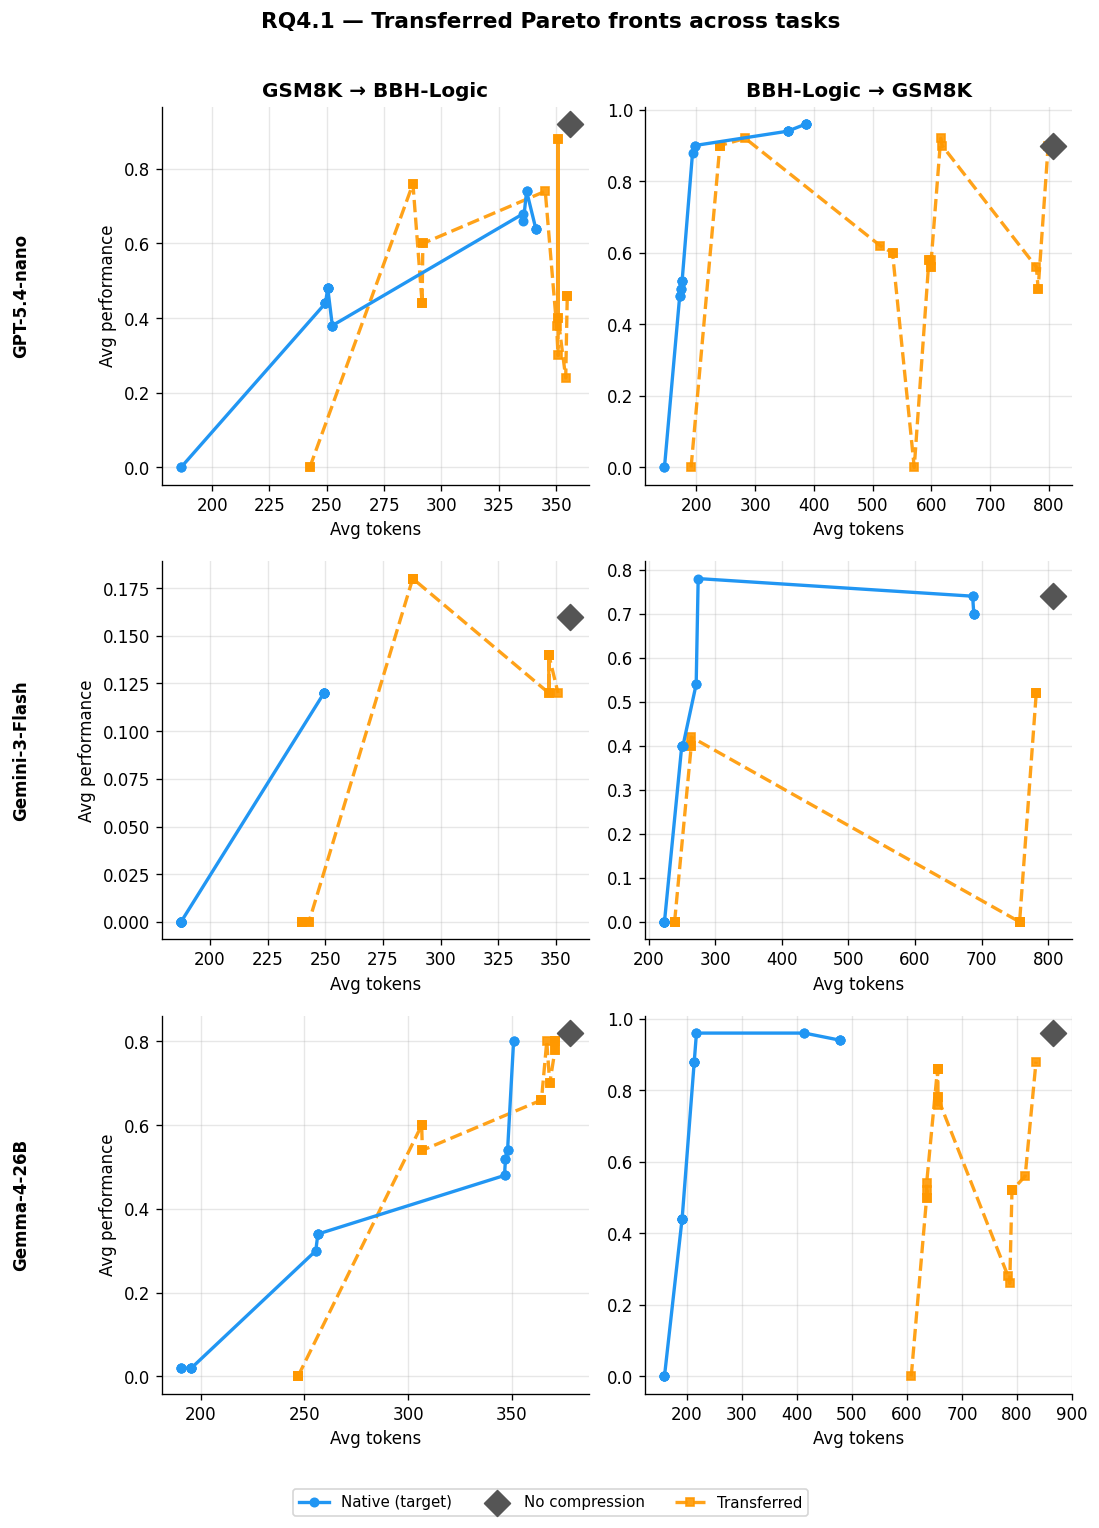

In [10]:
TASK_LABEL_MAP = {stem: lbl for stem, lbl, _ in TASKS}

def rq4_transfer_grid():
    models_with_transfer = [
        (lbl, mdir) for lbl, mdir, _ in MODELS
        if any(f'transfer_{s}_to_{t}' in RESULTS[mdir] for s, t in TRANSFER_PAIRS)
    ]
    if not models_with_transfer:
        print('No transfer results available.')
        return

    # pairs actually available across any model
    pairs_avail = list(dict.fromkeys(
        (s, t) for s, t in TRANSFER_PAIRS
        for _, mdir in models_with_transfer
        if f'transfer_{s}_to_{t}' in RESULTS[mdir]
    ))

    nrows = len(models_with_transfer)
    ncols = len(pairs_avail)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(4.5 * ncols, 4 * nrows), squeeze=False)

    legend_handles = {}

    for ri, (mlabel, mdir) in enumerate(models_with_transfer):
        for ci, (src, tgt) in enumerate(pairs_avail):
            ax = axes[ri][ci]
            src_lbl = TASK_LABEL_MAP.get(src, src)
            tgt_lbl = TASK_LABEL_MAP.get(tgt, tgt)

            if ri == 0:
                ax.set_title(f'{src_lbl} → {tgt_lbl}', fontweight='bold')
            if ci == 0:
                ax.annotate(mlabel, xy=(-0.35, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')
            ax.set_xlabel('Avg tokens')
            ax.set_ylabel('Avg performance' if ci == 0 else '')

            key = f'transfer_{src}_to_{tgt}'
            tr  = RESULTS[mdir].get(key)
            nat = RESULTS[mdir].get(tgt)

            if tr is None:
                ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes,
                        ha='center', va='center', color='gray')
                continue

            # Native target Pareto front
            if nat is not None:
                ntok, nperf = pareto_xy_json(nat['pareto_solutions'], 'test')
                order = np.argsort(ntok)
                h, = ax.plot(ntok[order], nperf[order], 'o-', color=NSGA2_COLOR,
                             lw=2, markersize=5, label='Native (target)', zorder=6)
                legend_handles.setdefault('Native (target)', h)

                # No-compression reference
                ref = next((b for b in nat['baselines'] if b['name'] == 'no_compression'), None)
                if ref:
                    rt = ref.get('test_avg_tokens') or ref['search_avg_tokens']
                    rp = ref.get('test_avg_performance') or ref['search_avg_performance']
                    h = ax.scatter(rt, rp, s=120, color='#555555', marker='D',
                                   zorder=7, label='No compression')
                    legend_handles.setdefault('No compression', h)

            # Transferred solutions
            tr_sols = tr['solutions']
            ttok  = np.array([s.get('test_avg_tokens')       or s['search_avg_tokens']      for s in tr_sols])
            tperf = np.array([s.get('test_avg_performance')  or s['search_avg_performance'] for s in tr_sols])
            order = np.argsort(ttok)
            h, = ax.plot(ttok[order], tperf[order], 's--', color='#FF9800',
                         lw=2, markersize=5, label=f'Transferred (from {src_lbl})', zorder=5, alpha=0.9)
            legend_handles.setdefault(f'Transferred', h)

    handles = list(legend_handles.values())
    labels  = list(legend_handles.keys())
    fig.legend(handles, labels, loc='lower center',
               ncol=min(4, len(labels)),
               bbox_to_anchor=(0.5, -0.04), frameon=True, fontsize=9)
    fig.suptitle('RQ4.1 — Transferred Pareto fronts across tasks',
                 fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


rq4_transfer_grid()


### RQ4.2 — Operator usage distribution in Pareto-optimal solutions

Heatmap showing how frequently each operator appears across Pareto-optimal solutions,
broken down by model and task. Colour = fraction of Pareto solutions that include the operator.

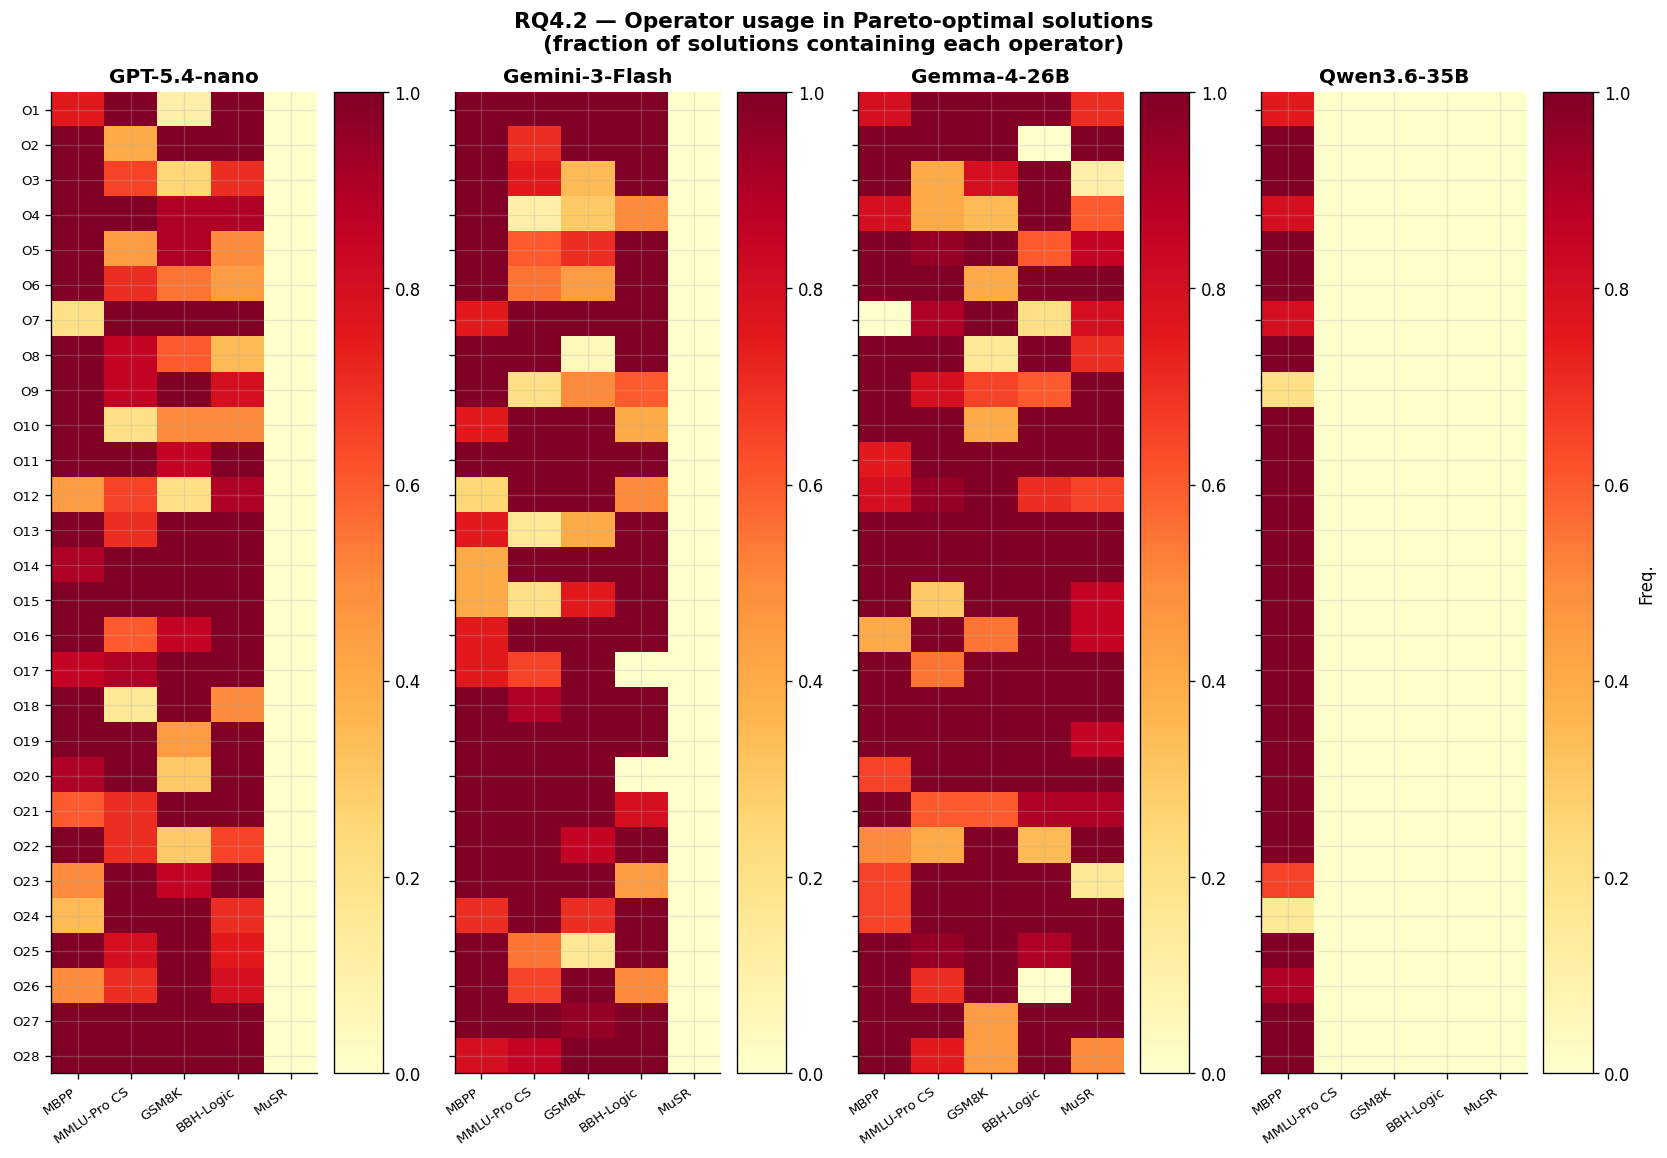

In [11]:
def collect_operator_usage():
    """Return DataFrame with columns [model, task, operator, frequency]."""
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            sols = d['pareto_solutions']
            if not sols:
                continue
            # Count raw operator IDs (without section prefix)
            op_counts = Counter()
            for sol in sols:
                for op_id in sol.get('transformation_ids', []):
                    # Strip section prefix (e.g. 'O3@instruction' -> 'O3')
                    base = op_id.split('@')[0]
                    op_counts[base] += 1
            for op, cnt in op_counts.items():
                rows.append({
                    'model': mlabel, 'task': tlabel,
                    'operator': op,
                    'frequency': cnt / len(sols),
                })
    return pd.DataFrame(rows)


df_ops = collect_operator_usage()

if df_ops.empty:
    print('No operator usage data available.')
else:
    # Sort operators by their numeric ID
    all_ops = sorted(df_ops['operator'].unique(),
                     key=lambda x: int(x.lstrip('O')) if x.lstrip('O').isdigit() else 999)

    models_present = [lbl for lbl, _, _ in MODELS if lbl in df_ops['model'].unique()]
    tasks_present  = [lbl for _, lbl, _ in TASKS  if lbl in df_ops['task'].unique()]

    # One heatmap per model, operators on y, tasks on x
    ncols = len(models_present)
    fig, axes = plt.subplots(1, ncols,
                             figsize=(3.5 * ncols, max(6, len(all_ops) * 0.35)),
                             squeeze=False)

    for ci, mlabel in enumerate(models_present):
        ax = axes[0][ci]
        sub = df_ops[df_ops['model'] == mlabel]
        pivot = (sub.groupby(['operator', 'task'])['frequency']
                    .mean()
                    .unstack(fill_value=0)
                    .reindex(index=all_ops, columns=tasks_present, fill_value=0))

        im = ax.imshow(pivot.values, aspect='auto', cmap='YlOrRd',
                       vmin=0, vmax=1, interpolation='nearest')
        ax.set_xticks(range(len(tasks_present)))
        ax.set_xticklabels(tasks_present, rotation=35, ha='right', fontsize=8)
        ax.set_yticks(range(len(all_ops)))
        ax.set_yticklabels(all_ops if ci == 0 else [], fontsize=8)
        ax.set_title(mlabel, fontweight='bold')
        plt.colorbar(im, ax=ax, label='Freq.' if ci == ncols - 1 else '')

    fig.suptitle('RQ4.2 — Operator usage in Pareto-optimal solutions\n'
                 '(fraction of solutions containing each operator)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


### RQ4.2b — Operator usage aggregated across models (bar chart)

Average operator frequency collapsed across all models, split by task.

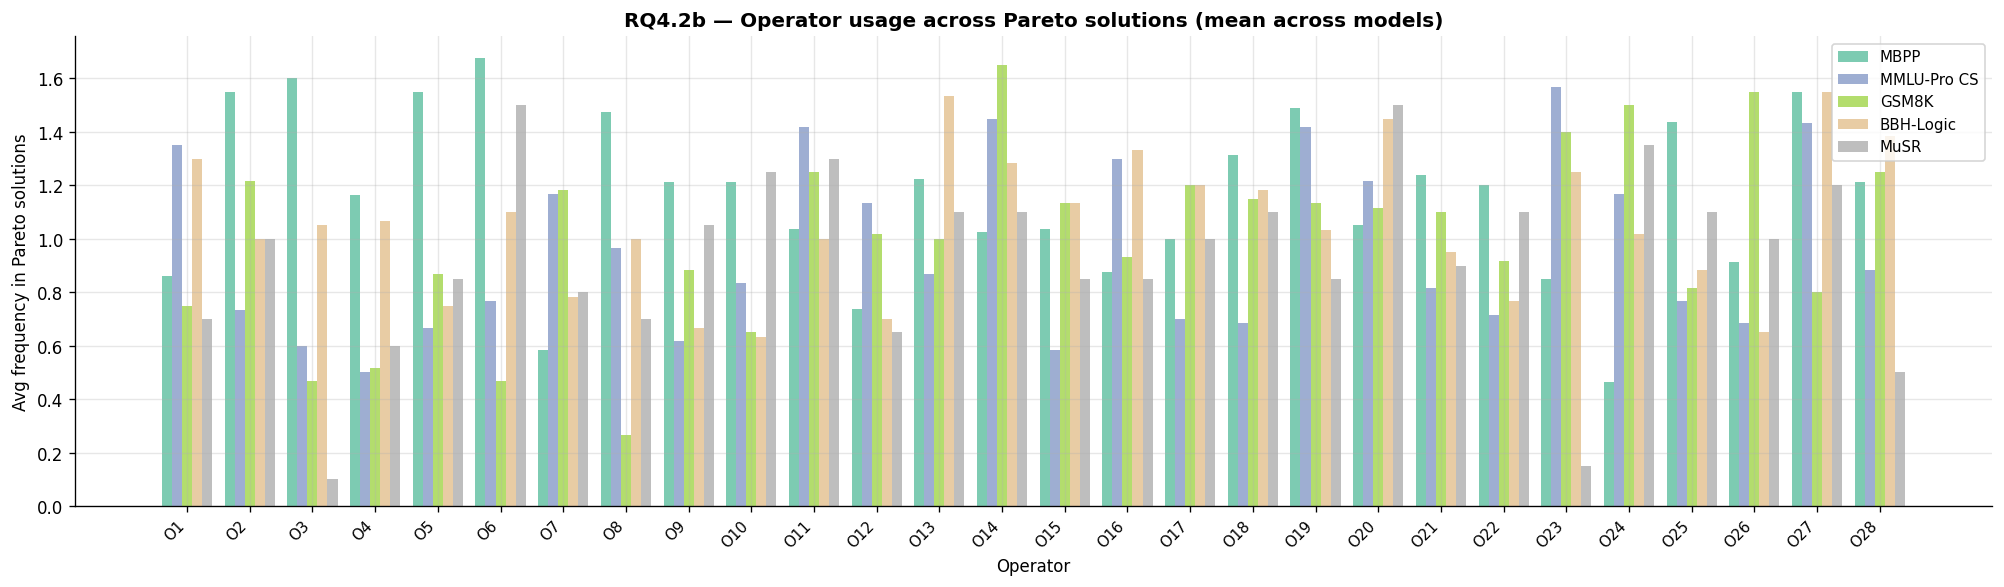

In [12]:
if not df_ops.empty:
    tasks_present  = [lbl for _, lbl, _ in TASKS if lbl in df_ops['task'].unique()]
    task_colors_map = {t: c for t, c in zip(tasks_present,
                                              plt.cm.Set2(np.linspace(0, 1, len(tasks_present))))}

    # Mean frequency across models
    agg = (df_ops.groupby(['operator', 'task'])['frequency']
               .mean()
               .reset_index())
    pivot = (agg.pivot(index='operator', columns='task', values='frequency')
               .reindex(index=all_ops, columns=tasks_present, fill_value=0))

    fig, ax = plt.subplots(figsize=(max(10, len(all_ops) * 0.6), 5))
    x = np.arange(len(all_ops))
    width = 0.8 / len(tasks_present)
    for i, task in enumerate(tasks_present):
        ax.bar(x + i * width, pivot[task].values, width,
               label=task, color=task_colors_map[task], alpha=0.85)

    ax.set_xticks(x + width * (len(tasks_present) - 1) / 2)
    ax.set_xticklabels(all_ops, rotation=45, ha='right', fontsize=9)
    ax.set_ylabel('Avg frequency in Pareto solutions')
    ax.set_xlabel('Operator')
    ax.legend(loc='upper right', fontsize=9)
    ax.set_title('RQ4.2b — Operator usage across Pareto solutions (mean across models)',
                 fontweight='bold')
    plt.tight_layout()
    plt.show()
